# 07 · Análisis del monitoreo

Proyecto Centinela (PSet 4). Umbrales, deriva, desempeño, alertas, reentrenamientos, resultado de negocio y ética de la simulación de producción. Lee `docs/` (exportes de `CENTINELA.PRODUCCION`) y vuelve a calcular la ética con `monitoreo/etica.py`. No cambia nada en Snowflake ni en MLflow.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(RAIZ / "src"), str(RAIZ / "monitoreo")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
# Paleta (skill de visualización): categórica en orden fijo; estados reservados para severidad.
MODELO, REGLAS, SIN_MODELO, GRIS = "#257de0", "#f47230", "#00b894", "#666666"
SEV = {"crítica": "#dc3c3d", "alta": "#f18a59", "media": "#fbb315", "baja": "#9c9c9c"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "figure.dpi": 110, "font.size": 9})
D1, D2 = 10, 14
def franjas(ax):
    ax.axvspan(D1 - .5, D2 - .5, color=GRIS, alpha=.07, lw=0); ax.axvspan(D2 - .5, 25.5, color=GRIS, alpha=.14, lw=0)
    y = ax.get_ylim()[1]
    ax.text(D1 - .3, y, "D1", va="top", fontsize=8, color=GRIS); ax.text(D2 - .3, y, "D1+D2", va="top", fontsize=8, color=GRIS)
D = RAIZ / "docs"
mon = pd.read_csv(D / "monitoreo.csv"); al = pd.read_csv(D / "alertas.csv")
re = pd.read_csv(D / "simulacion/reentrenamientos_simulacion.csv"); U = json.loads((D / "monitoreo/umbrales.json").read_text())
des = mon[mon.grupo == "desempeño"].pivot_table(index=["lote", "modelo_version"], columns="metrica", values="valor").reset_index()
def reentrenos(ax):
    for r in re.itertuples():
        ax.axvline(r.paso, color="#0aac23" if r.decision == "aprobada" else GRIS, ls="-" if r.decision == "aprobada" else "--", lw=1.4)
        ax.text(r.paso + .1, ax.get_ylim()[0], f"paso {r.paso}\n{r.decision}\nv{r.challenger_version}", fontsize=7, va="bottom", color="#191919")
print(len(mon), "métricas,", len(al), "alertas,", len(re), "reentrenamientos")

2758 métricas, 68 alertas, 4 reentrenamientos


## 1. Umbral de desempeño: la CV del PSet 3 a escala semanal

,valor,semanas OOF bajo el umbral,lotes sin alterar bajo el umbral
umbral_por_pliegue,0.929,8,"[0, 14]"
umbral_semanal,0.908084,2,[]


AUC-PR semanal OOF: 0.9626 ± 0.0273 -> umbral 0.9081


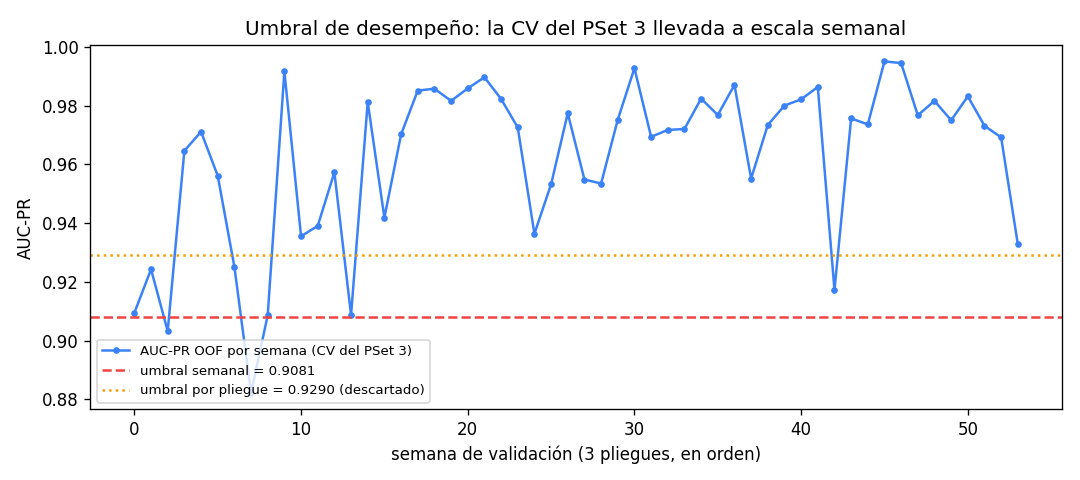

In [2]:
c = U["desempeno"]["comparacion"]
display(pd.DataFrame({k: {"valor": v["valor"], "semanas OOF bajo el umbral": v["semanas_oof_bajo_umbral"],
                          "lotes sin alterar bajo el umbral": v["lotes_prueba_sin_alterar_bajo_umbral"]} for k, v in c.items()}).T)
print(f"AUC-PR semanal OOF: {U['desempeno']['auc_pr_semanal_media']:.4f} ± {U['desempeno']['auc_pr_semanal_desviacion']:.4f} -> umbral {U['desempeno']['umbral_auc_pr']:.4f}")
display(Image(D / "monitoreo/umbral_desempeno.png"))

## 2. Deriva de datos (PSI frente a la misma semana de 2019)

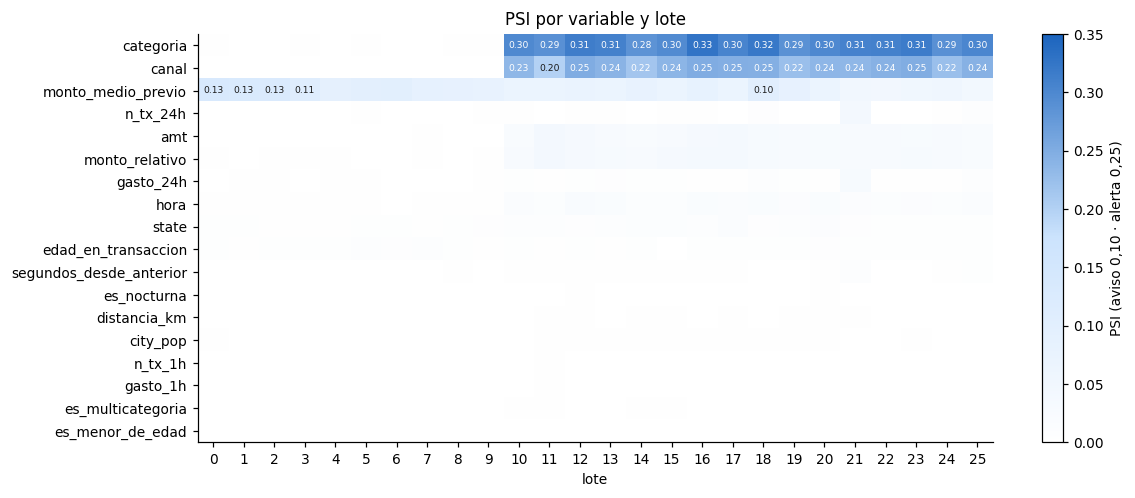

PSI máximo en lotes sin alterar (0-9): 0.132 | en lotes con D1: 0.326 ( categoria )


In [3]:
psi = mon[(mon.grupo == "datos") & (mon.metrica == "psi")].pivot_table(index="variable", columns="lote", values="valor")
psi = psi.loc[psi.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(psi.values, aspect="auto", cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#ffffff", "#cce3fd", "#1b64be"]), vmin=0, vmax=.35)
ax.set_yticks(range(len(psi)), psi.index); ax.set_xticks(range(psi.shape[1]), psi.columns); ax.grid(False)
for i in range(psi.shape[0]):
    for j in range(psi.shape[1]):
        if psi.values[i, j] >= U["psi"]["aviso"]:
            ax.text(j, i, f"{psi.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="#ffffff" if psi.values[i, j] > .2 else "#191919")
fig.colorbar(im, ax=ax, label="PSI (aviso 0,10 · alerta 0,25)"); ax.set_xlabel("lote"); ax.set_title("PSI por variable y lote")
fig.tight_layout(); fig.savefig(D / "monitoreo/psi_por_lote.png", dpi=120); plt.show()
print("PSI máximo en lotes sin alterar (0-9):", round(psi.loc[:, :9].max().max(), 3), "| en lotes con D1:", round(psi.loc[:, 10:].max().max(), 3), "(", psi.loc[:, 10:].max(axis=1).idxmax(), ")")

## 3. Desempeño por lote etiquetado y reentrenamientos

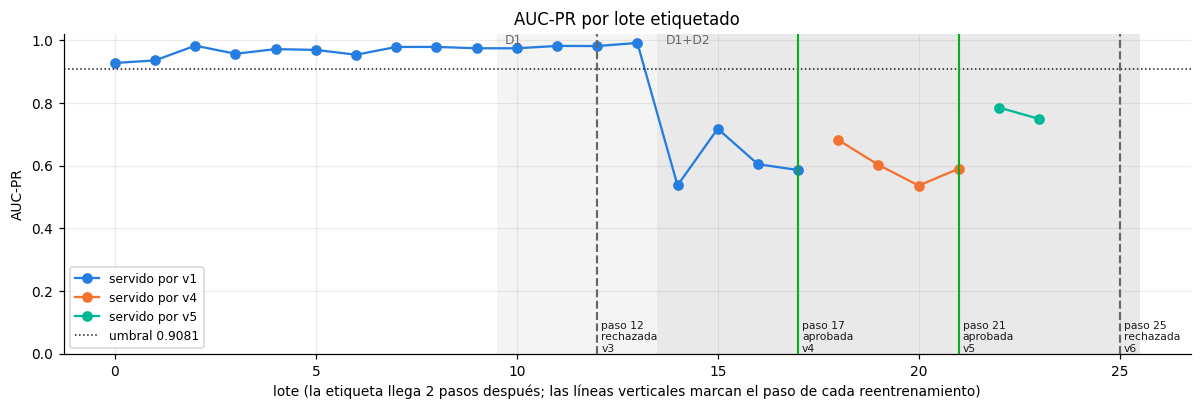

,paso,motivo,lote_evaluacion,champion_version,challenger_version,perdida_x1000_champion,perdida_x1000_challenger,mejora_x1000,recomendacion,decision
0,12,calendario,10,1,3,16.20,18.30,-2.10,rechazar,rechazada
1,17,desempeño,15,1,4,446.08,368.45,77.63,promover,aprobada
2,21,desempeño,19,4,5,241.63,124.72,116.91,promover,aprobada
3,25,desempeño,23,5,6,96.74,101.21,-4.48,rechazar,rechazada


In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for v, d in des.groupby("modelo_version"):
    ax.plot(d.lote, d.auc_pr, "o-", label=f"servido por v{v}", color={"1": MODELO, "4": REGLAS, "5": SIN_MODELO}.get(str(v), GRIS))
ax.axhline(U["desempeno"]["umbral_auc_pr"], color="#191919", ls=":", lw=1, label=f"umbral {U['desempeno']['umbral_auc_pr']:.4f}")
ax.set_ylim(0, 1.02); franjas(ax); reentrenos(ax)
ax.set_xlabel("lote (la etiqueta llega 2 pasos después; las líneas verticales marcan el paso de cada reentrenamiento)"); ax.set_ylabel("AUC-PR")
ax.legend(fontsize=8, loc="lower left"); ax.set_title("AUC-PR por lote etiquetado")
fig.tight_layout(); fig.savefig(D / "monitoreo/auc_pr_por_lote.png", dpi=120); plt.show()
display(re[["paso", "motivo", "lote_evaluacion", "champion_version", "challenger_version", "perdida_x1000_champion",
            "perdida_x1000_challenger", "mejora_x1000", "recomendacion", "decision"]].round(2))

## 4. Alertas

Los lotes 0 a 9 no tienen ninguna alteración: cualquier alerta de severidad media o mayor ahí sería una falsa alarma.

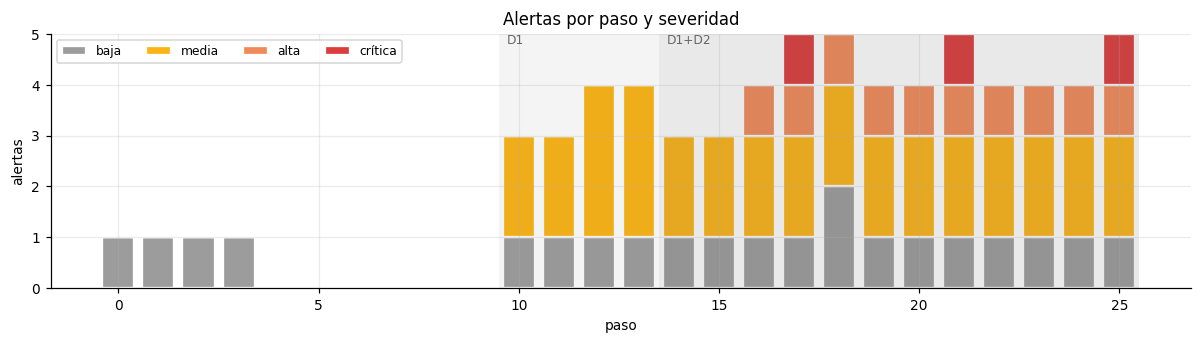

Falsas alarmas (severidad media o mayor) en lotes sin alterar: 0
Avisos informativos en lotes sin alterar: [{'paso': 0, 'variable': 'monto_medio_previo', 'valor': 0.132}, {'paso': 1, 'variable': 'monto_medio_previo', 'valor': 0.128}, {'paso': 2, 'variable': 'monto_medio_previo', 'valor': 0.127}, {'paso': 3, 'variable': 'monto_medio_previo', 'valor': 0.109}]


,id_alerta,severidad,veces
0,DAT-PSI,media,16
1,MOD-DES-1,alta,10
2,MOD-DES-2,crítica,3
3,MOD-TASA,media,2
4,SIS-VOL,media,16


In [5]:
orden = ["crítica", "alta", "media", "baja"]
t = al.pivot_table(index="paso", columns="severidad", values="id_alerta", aggfunc="count").reindex(columns=orden).fillna(0).reindex(range(26), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.2)); base = np.zeros(len(t))
for s in orden[::-1]:
    ax.bar(t.index, t[s], bottom=base, color=SEV[s], label=s, edgecolor="#ffffff", linewidth=1.5); base += t[s].values
ax.set_xlabel("paso"); ax.set_ylabel("alertas"); ax.legend(fontsize=8, ncol=4); ax.set_title("Alertas por paso y severidad"); franjas(ax)
fig.tight_layout(); fig.savefig(D / "monitoreo/alertas_por_paso.png", dpi=120); plt.show()
sin_alt = al[(al.lote < 10) & (al.severidad != "baja")]
print("Falsas alarmas (severidad media o mayor) en lotes sin alterar:", len(sin_alt))
print("Avisos informativos en lotes sin alterar:", al[(al.lote < 10) & (al.severidad == "baja")][["paso", "variable", "valor"]].round(3).to_dict("records"))
display(al[al.severidad != "baja"].groupby(["id_alerta", "severidad"]).size().rename("veces").reset_index())

## 5. Resultado de negocio

Pérdida neta = fraude no detectado + USD 5 por falsa alarma. Se compara con las reglas fijas del PSet 1 y con no hacer nada (aprobar todo), lote por lote, con los reentrenamientos marcados.

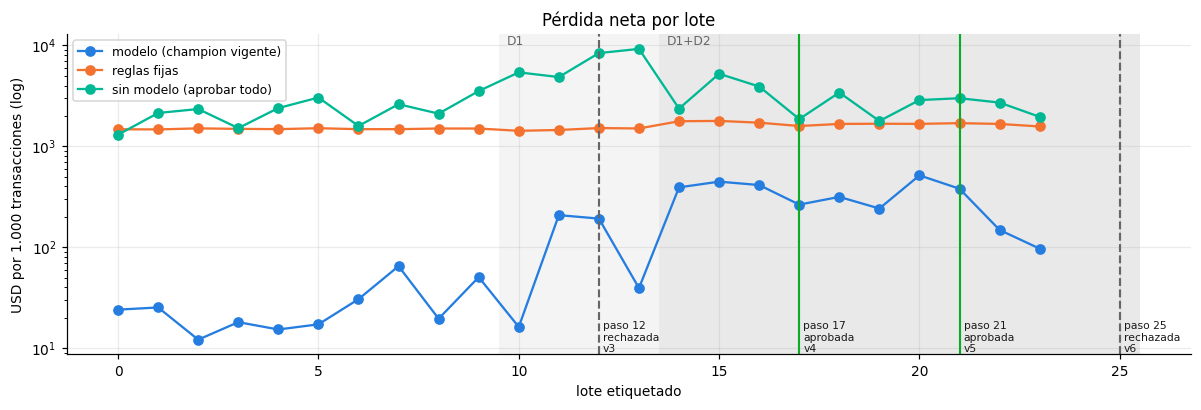

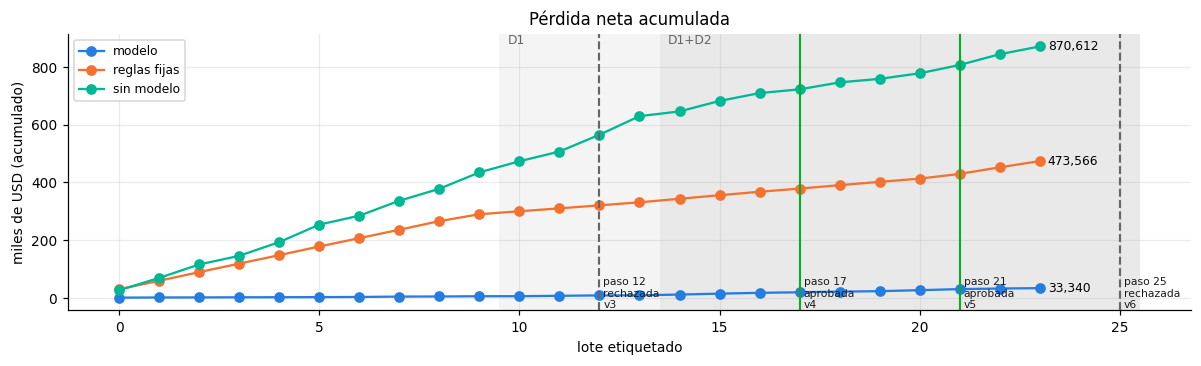

Lotes 0-23 (308,056 transacciones): modelo 33,340 USD | reglas 473,566 USD | sin modelo 870,612 USD
Ahorro frente a las reglas: 93.0%; frente a no hacer nada: 96.2%


In [6]:
n = des.assign(modelo=1000 * des.perdida_neta / des.filas, reglas=1000 * des.perdida_reglas / des.filas, sin_modelo=1000 * des.perdida_sin_modelo / des.filas)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(n.lote, n.modelo, "o-", color=MODELO, label="modelo (champion vigente)"); ax.plot(n.lote, n.reglas, "o-", color=REGLAS, label="reglas fijas")
ax.plot(n.lote, n.sin_modelo, "o-", color=SIN_MODELO, label="sin modelo (aprobar todo)")
ax.set_yscale("log"); franjas(ax); reentrenos(ax); ax.set_ylabel("USD por 1.000 transacciones (log)"); ax.set_xlabel("lote etiquetado")
ax.legend(fontsize=8, loc="upper left"); ax.set_title("Pérdida neta por lote")
fig.tight_layout(); fig.savefig(D / "negocio/negocio_por_lote.png", dpi=120); plt.show()
acum = n[["perdida_neta", "perdida_reglas", "perdida_sin_modelo"]].cumsum()
fig, ax = plt.subplots(figsize=(11, 3.4))
for col, color, et in [("perdida_neta", MODELO, "modelo"), ("perdida_reglas", REGLAS, "reglas fijas"), ("perdida_sin_modelo", SIN_MODELO, "sin modelo")]:
    ax.plot(n.lote, acum[col] / 1000, "o-", color=color, label=et); ax.text(n.lote.iloc[-1] + .2, acum[col].iloc[-1] / 1000, f"{acum[col].iloc[-1]:,.0f}", fontsize=8, va="center")
franjas(ax); reentrenos(ax); ax.set_ylabel("miles de USD (acumulado)"); ax.set_xlabel("lote etiquetado"); ax.legend(fontsize=8); ax.set_title("Pérdida neta acumulada")
fig.tight_layout(); fig.savefig(D / "negocio/negocio_acumulado.png", dpi=120); plt.show()
tot = n[["perdida_neta", "perdida_reglas", "perdida_sin_modelo", "filas"]].sum()
print(f"Lotes 0-23 ({int(tot.filas):,} transacciones): modelo {tot.perdida_neta:,.0f} USD | reglas {tot.perdida_reglas:,.0f} USD | sin modelo {tot.perdida_sin_modelo:,.0f} USD")
print(f"Ahorro frente a las reglas: {1 - tot.perdida_neta / tot.perdida_reglas:.1%}; frente a no hacer nada: {1 - tot.perdida_neta / tot.perdida_sin_modelo:.1%}")
n[["lote", "modelo_version", "prevalencia", "auc_pr", "modelo", "reglas", "sin_modelo"]].round(3).to_csv(D / "negocio/negocio_por_lote.csv", index=False)

## 6. Ética: subgrupos y criterios de retirada

,ventana,dimension,grupo,transacciones,fraudes,auc_pr,recall_pct,falsas_alarmas_pct_legitimas,tasa_aprobar_pct,tasa_verificar_pct,tasa_retener_pct
0,sin alterar (0-9),total,total,194522,850,0.964,97.294,0.282,99.294,0.276,0.430
1,sin alterar (0-9),genero,hombre,88129,358,0.982,98.883,0.243,99.357,0.222,0.421
2,sin alterar (0-9),genero,mujer,106393,492,0.950,96.138,0.315,99.241,0.321,0.438
3,sin alterar (0-9),grupo_edad,25 a 39,61312,282,0.965,97.872,0.305,99.246,0.303,0.450
4,sin alterar (0-9),grupo_edad,40 a 59,73015,300,0.943,95.333,0.296,99.314,0.294,0.392
5,sin alterar (0-9),grupo_edad,60 o más,43289,222,0.983,98.649,0.269,99.226,0.261,0.513
6,sin alterar (0-9),grupo_edad,menos de 25,16906,46,0.990,100.000,0.178,99.550,0.136,0.313
7,todos los etiquetados (0-23),total,total,308056,1956,0.846,82.209,0.322,99.158,0.328,0.514
8,todos los etiquetados (0-23),genero,hombre,138972,909,0.856,82.618,0.270,99.191,0.275,0.534
9,todos los etiquetados (0-23),genero,mujer,169084,1047,0.836,81.853,0.364,99.131,0.371,0.497


,error,casos,costo_usd,quien_lo_asume
0,falso negativo (fraude aprobado),348,28415.0,el banco (contracargo del monto) y el cliente ...
1,falso positivo en verificar (legítima con OTP ...,871,4355.0,"el banco (USD 5 por verificación, supuesto del..."
2,falso positivo en retener (legítima retenida p...,114,570.0,el cliente legítimo (compra detenida hasta la ...


,criterio,umbral,observado,se_activo
0,R1 negocio: el modelo pierde más que las regla...,> 1 en 2 lotes etiquetados seguidos,máximo 0.309 (lote 20); lotes > 1: 0,False
1,R2 equidad: falsas alarmas desiguales entre su...,> 1.25 (regla de los 4/5) y diferencia signifi...,genero: 8 de 21 ventanas sobre el umbral (coci...,True
2,R3 montos fuera de soporte (hallazgo B1),> 1 % del lote; y cualquier transacción en esa...,máximo 0.159 % del lote (lote 12); 252 transac...,False
3,R4 sistema: el servicio no responde a tiempo,p95 > 200 ms o 5xx > 1 % en el lote,p95 máximo 17.0 ms; 5xx totales 0,False


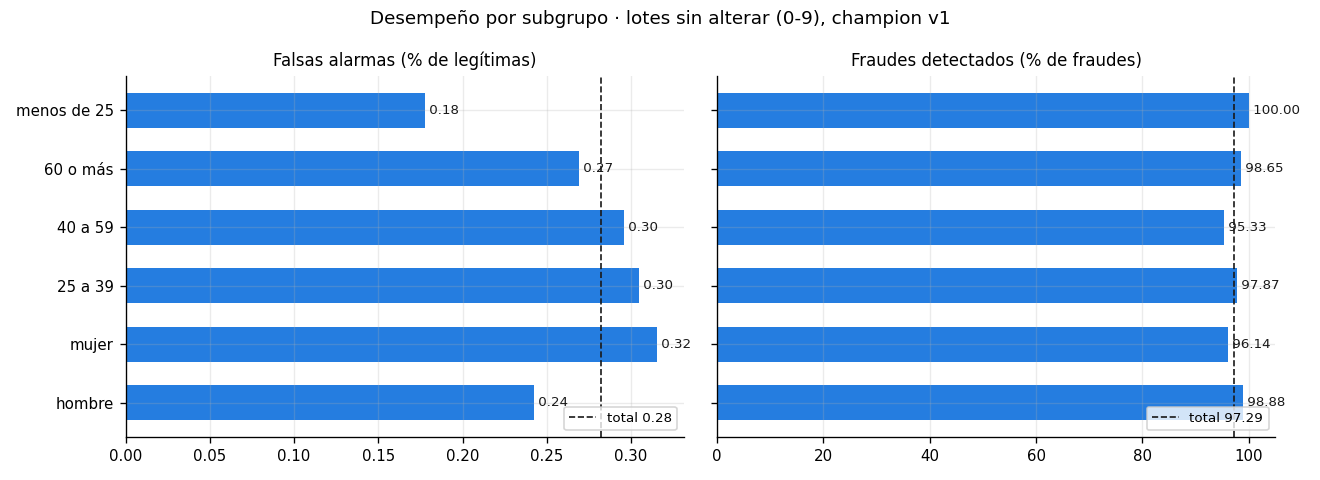

In [7]:
import etica
r = etica.main()
display(r["subgrupos"][["ventana", "dimension", "grupo", "transacciones", "fraudes", "auc_pr", "recall_pct", "falsas_alarmas_pct_legitimas",
                        "tasa_aprobar_pct", "tasa_verificar_pct", "tasa_retener_pct"]].round(3))
display(r["costos"][["error", "casos", "costo_usd", "quien_lo_asume"]].round(0))
display(r["criterios"][["criterio", "umbral", "observado", "se_activo"]])
display(Image(D / "etica/subgrupos.png"))

**Conclusiones.** Ver `docs/simulacion/resultados.md` y `docs/etica/etica.md`. La deriva de datos sola (D1) no disparó reentrenamientos y ningún lote sin alterar dio alertas de severidad media o mayor; la deriva conceptual (D2) hizo caer la AUC-PR y disparó 3 reentrenamientos (2 promovidos). El criterio de equidad R2 se activa: hay más falsas alarmas para las mujeres que para los hombres, y queda como hallazgo y revisión pendiente.